In [3]:
import importlib
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, "kev")

import data.persona as _persona_mod
import data.base as _base_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon as _grummon_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _issp_mod,
    _twin2k_mod,
    _grummon_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon import load_grummon
from data.issp import load_issp_df
from data.twin2k import load_twin2k_df
from training import GroupedTrainer, free_gpu

## 1. Load & Build Persona Datasets

In [4]:
INCLUDE_COUNTRY = False

VALID_ISSP_QIDS = ["2020:v12", "2020:v6", "2020:v28", "2020:v42"]
VALID_TWIN_QIDS = [f"twin2k:QID9_{i:03d}" for i in range(89, 100)] + ["twin2k:QID41", "twin2k:QID163", "twin2k:QID165"]
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS

all_df = pd.concat([load_issp_df(), load_twin2k_df()], ignore_index=True)
if not set(VALID_QIDS) <= set(all_df["qid"]):
    raise KeyError(f"Valid qids not found: {sorted(set(VALID_QIDS) - set(all_df['qid']))}")

train_records = build_persona_dataset(
    all_df[~all_df["qid"].isin(VALID_QIDS)], attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_resp"
)
valid_grouped = build_eval_set(
    all_df[all_df["qid"].isin(VALID_QIDS)],
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid", valid=True,
)
grummon_grouped = load_grummon(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)

eval_records = [valid_grouped, grummon_grouped]

print(
    f"Train records : {len(train_records):,}\n"
    f"Eval sets     : valid={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon={len(grummon_grouped['records']):,} ({len(grummon_grouped['packed_views']):,} states)"
)

Loaded 1,881,950 records from train_records_resp_minNone_5099daf2.pkl
Loaded 13,183 records from valid_records_minNone_dc60d6c3.pkl
Train records : 1,881,950
Eval sets     : valid=13,183 (3,879 states), grummon=33,798 (3,652 states)


## 2. Configure & Instantiate `GroupedTrainer`


In [3]:
resume = False
val_every = 50
epochs = 1
lr = 5e-5
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k-grouped-newvalid",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped-newvalid",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,  # bf16 autocast for eval only; training stays fp32
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = GroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    samples_per_epoch=None,
    resume=resume,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
run_name,kev-0.8b-resp-issp+twin2k-grouped-newvalid
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
weights_dtype,bf16
use_bf16,True
eval_bf16,True
gradient_checkpointing,False
max_questions_per_group,32
max_chars_per_group,20000


## Run eval

In [4]:
# Test one full evaluation loop across all eval sets with progress bars:
eval_summaries, eval_extra_dfs = trainer.evaluate(show_progress=True)
for s in trainer.eval_sets:
    name = s["name"]
    st = s["last_stats"]
    print(
        f"{name}: {st['n_batches']} batches ({st['n_views_run']:,} states, {st['n_records']:,} records) "
        f"in {st['total_sec']:.2f}s (gpu={st['gpu_sec']:.2f}s)"
    )
    display(eval_summaries[name].to_frame(name=name))

Evaluating valid (shared-state):   0%|          | 0/23 [00:00<?, ?batch/s]

Evaluating grummon (shared-state):   0%|          | 0/46 [00:00<?, ?batch/s]

valid: 23 batches (3,879 states, 13,183 records) in 15.39s (gpu=15.30s)


,valid
ce,2.426183
dist_kl,2.426183


grummon: 46 batches (3,652 states, 33,798 records) in 31.39s (gpu=31.18s)


,grummon
ce,2.022351
dist_kl,2.022351
OLS MAPE (%),104.125182
OLS MSE,0.014924
OLS MAE,0.116413
Spearman rho,-0.900000


## Verify fused weights

In [5]:
# Verify model train mode, weights, module attributes, forward loss, and backward gradients are identical pre/post fused eval:
import importlib
import types
import torch
import data.base as _base_mod
import training.trainer as _trainer_mod
importlib.reload(_base_mod)
importlib.reload(_trainer_mod)
from data.base import fused_eval_context, make_grouped_view

trainer.model.train()
for _, _m in trainer.model.net.lm.named_modules():
    if "forward" in _m.__dict__ and isinstance(_m.__dict__["forward"], types.MethodType) and _m.__dict__["forward"].__func__ is type(_m).forward:
        del _m.__dict__["forward"]
sample_group = trainer._epoch_groups_for(0)[0][:8]
enc, targets = trainer.model.prepare(make_grouped_view(sample_group))

def _sample_loss():
    torch.manual_seed(1234)
    torch.cuda.manual_seed_all(1234)
    with trainer._autocast():
        logits = trainer.model.forward([enc], shared_prefix=True)[0]
    return torch.stack([
        -(q["target"].to(trainer.device) * torch.log_softmax(z.float(), dim=-1)).sum()
        for z, q in zip(logits, targets, strict=True)
    ]).mean()

trainer.model.net.zero_grad(set_to_none=True)
pre_loss = _sample_loss()
pre_loss.backward()
pre_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
pre_loss2 = _sample_loss()
pre_loss2.backward()
pre_grads2 = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
baseline_grad_diff = max((pre_grads[n] - pre_grads2[n]).abs().max().item() for n in pre_grads)
del pre_grads2
pre_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
pre_params = {n: (p.dtype, p.requires_grad, p.detach().clone()) for n, p in trainer.model.net.named_parameters()}

s0 = trainer.eval_sets[0]
b_encs = s0["encs"][:4] if s0["encs"] is not None else [trainer.model.prepare(v)[0] for v in s0["packed_views"][:4]]
trainer.model.eval()
eval_dtype = torch.bfloat16 if trainer.eval_bf16 else None
with torch.no_grad(), trainer._eval_autocast(), fused_eval_context(trainer.model, eval_dtype=eval_dtype):
    trainer.model.net.probs_batch(b_encs, [None] * len(b_encs), [False] * len(b_encs))
trainer.model.train()

post_dict_keys = {n: set(m.__dict__.keys()) for n, m in trainer.model.net.lm.named_modules()}
assert pre_dict_keys == post_dict_keys, "Module __dict__ keys changed!"
assert trainer.model.net.graphs is None, "CudaGraphs was not released!"
for n, p in trainer.model.net.named_parameters():
    dt, req_grad, t_pre = pre_params[n]
    assert p.dtype == dt and p.requires_grad == req_grad and torch.equal(p, t_pre), f"Param changed: {n}"

post_loss = _sample_loss()
post_loss.backward()
post_grads = {n: p.grad.detach().clone() for n, p in trainer.model.net.named_parameters() if p.grad is not None}
trainer.model.net.zero_grad(set_to_none=True)
free_gpu()

loss_diff = (pre_loss - post_loss).abs().item()
max_grad_diff = max((pre_grads[n] - post_grads[n]).abs().max().item() for n in pre_grads)
print(f"Pre/post fused eval check PASSED | training={trainer.model.training} | loss_diff={loss_diff:.3e} | max_grad_diff={max_grad_diff:.3e} (baseline backward atomicAdd noise={baseline_grad_diff:.3e})")

Pre/post fused eval check PASSED | training=True | loss_diff=0.000e+00 | max_grad_diff=5.371e-03 (baseline backward atomicAdd noise=5.859e-03)


## Test speed on train step

In [4]:
# Benchmark 1 full optimizer step (12 groups) across (weights_dtype, use_bf16) setups without mutating trainer state:
import random
import time
import numpy as np
import pandas as pd
import torch

macro_batch = trainer._epoch_groups_for(0)[:trainer.effective_groups_bs]
orig_use_bf16 = trainer.use_bf16
orig_trainable = {n: p.detach().clone() for n, p in trainer.model.net.named_parameters() if p.requires_grad}
orig_frozen = [(p, p.data.cpu()) for p in trainer.model.net.parameters() if not p.requires_grad]
rows = []

try:
    if trainer.gradient_checkpointing:
        trainer.model.enable_checkpointing()
    trainer.model.train()

    for label, w_dtype, use_bf16 in [
        ("fp32 weights + fp32 train (TF32)", torch.float32, False),
        ("fp32 weights + bf16 autocast", torch.float32, True),
        ("bf16 weights + bf16 autocast", torch.bfloat16, True),
    ]:
        for p, cpu_t in orig_frozen:
            p.data = cpu_t.to(device=trainer.device, dtype=w_dtype if cpu_t.is_floating_point() else cpu_t.dtype)
        for n, p in trainer.model.net.named_parameters():
            if p.requires_grad:
                p.data.copy_(orig_trainable[n])
        trainer.use_bf16 = use_bf16

        opt = torch.optim.AdamW(trainer.model.trainable_parameters(), lr=trainer.lr, weight_decay=trainer.weight_decay)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=trainer.lr, total_steps=trainer.total_steps, pct_start=trainer.pct_start)

        # Warmup on 1 group, then reset trainable weights before timing full 12-group step
        trainer.train_one_step(macro_batch[:1], optimizer=opt, scheduler=sched, step=0, total_steps=trainer.total_steps, rng=random.Random(0))
        for n, p in trainer.model.net.named_parameters():
            if p.requires_grad:
                p.data.copy_(orig_trainable[n])
        opt = torch.optim.AdamW(trainer.model.trainable_parameters(), lr=trainer.lr, weight_decay=trainer.weight_decay)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=trainer.lr, total_steps=trainer.total_steps, pct_start=trainer.pct_start)

        free_gpu()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        step_kls = trainer.train_one_step(macro_batch, optimizer=opt, scheduler=sched, step=0, total_steps=trainer.total_steps, rng=random.Random(0))
        torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        peak_gib = torch.cuda.max_memory_allocated() / (1024 ** 3)
        rows.append({
            "setup": label,
            "step_sec": round(dt, 3),
            "est_epoch_min": round(dt * trainer.steps_per_epoch / 60, 1),
            "peak_vram_gib": round(peak_gib, 2),
            "mean_train_kl": round(float(np.mean(step_kls)), 6),
        })
        del opt, sched
finally:
    trainer.use_bf16 = orig_use_bf16
    for p, cpu_t in orig_frozen:
        p.data = cpu_t.to(device=trainer.device)
    for n, p in trainer.model.net.named_parameters():
        if p.requires_grad:
            p.data.copy_(orig_trainable[n])
            p.grad = None
    free_gpu()

df_bench = pd.DataFrame(rows)
df_bench["speedup_vs_fp32"] = (df_bench["step_sec"].iloc[0] / df_bench["step_sec"]).round(2)
display(df_bench)

,setup,step_sec,est_epoch_min,peak_vram_gib,mean_train_kl,speedup_vs_fp32
0,fp32 weights + fp32 train (TF32),2.709,275.1,22.54,2.426063,1.00
1,fp32 weights + bf16 autocast,2.020,205.2,17.32,2.432151,1.34
2,bf16 weights + bf16 autocast,1.965,199.5,13.79,2.448095,1.38


## Second epoch Train

In [5]:
resume = False
val_every = 50
epochs = 1
lr = 5e-5
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"
init_from="runs/kev-0.8b-resp-issp+twin2k-grouped-newvalid/best"   
save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped-newvalid-ep2"
seed=1
warmup_steps = 200

if PRESET == "9b":
    trainer_cfg = dict(
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        eval_max_questions=384,
        eval_max_chars=144_000,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,  # bf16 autocast for eval only; training stays fp32
        eval_max_questions=1024,
        eval_max_chars=360_000,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = GroupedTrainer(
    init_from=init_from,
    save_dir=save_dir,
    train_records=train_records,
    eval_records=eval_records,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=warmup_steps,
    val_every=val_every,
    samples_per_epoch=None,
    resume=resume,
    seed=seed,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
run_name,kev-0.8b-resp-issp+twin2k-grouped-newvalid-ep2
save_dir,runs/kev-0.8b-resp-issp+twin2k-grouped-newvali...
init_from,runs/kev-0.8b-resp-issp+twin2k-grouped-newvali...
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,1
epochs,1
lr,0.00005


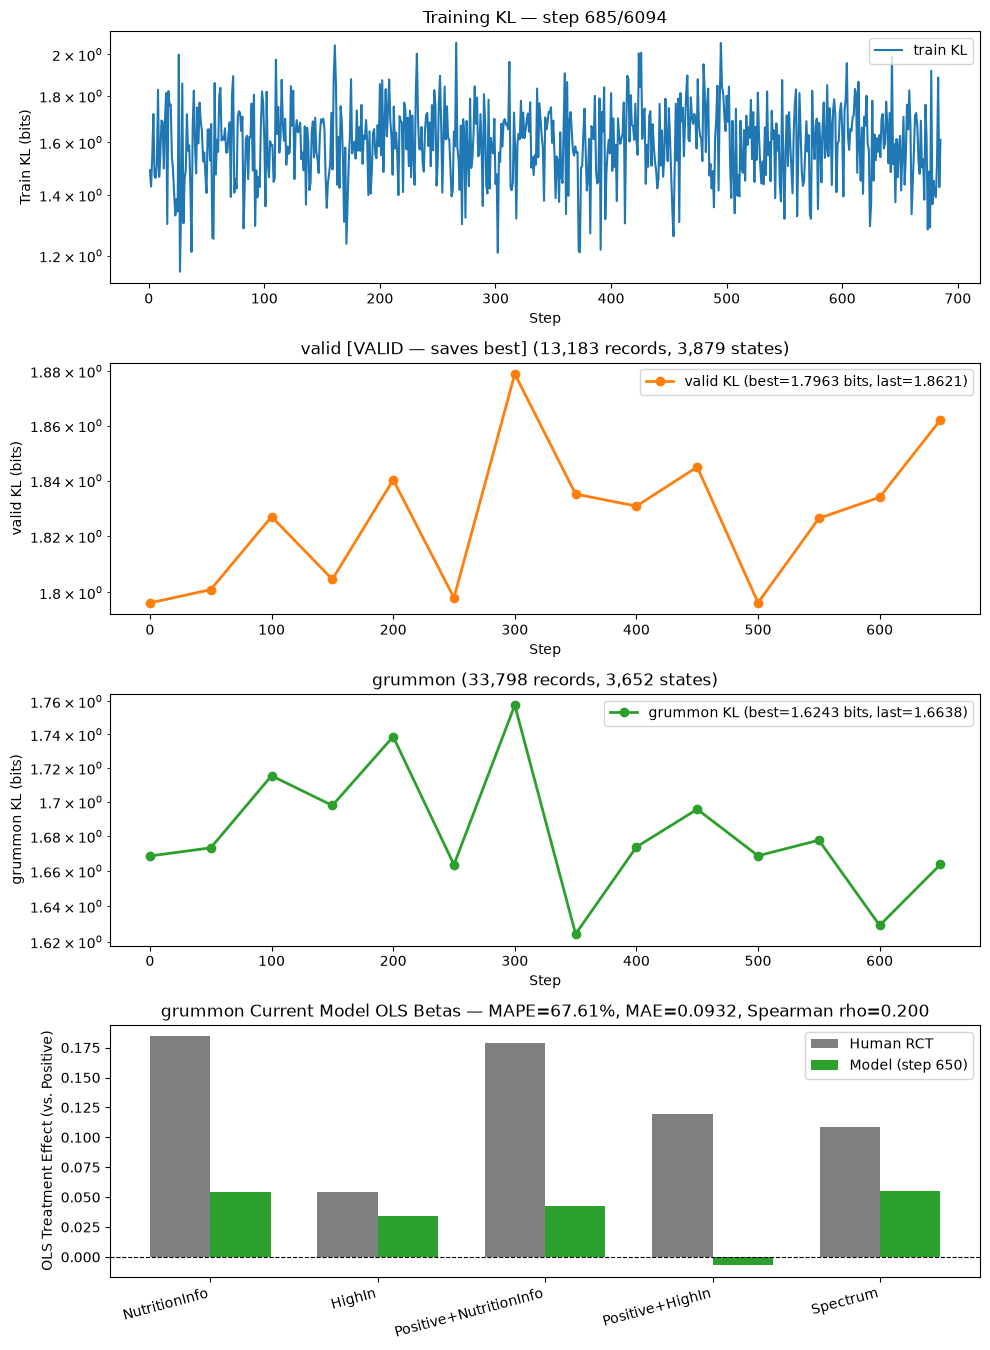

,epoch,step,train_kl,valid_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,1.7963,1.6686,60.63,0.0843,0.0092,0.2000
1,1,50,1.4072,1.8010,1.6733,59.23,0.0835,0.0093,0.2000
2,1,100,1.6063,1.8270,1.7154,59.43,0.0823,0.0091,0.2000
3,1,150,1.6827,1.8047,1.6979,60.90,0.0885,0.0103,-0.3000
4,1,200,1.8547,1.8403,1.7386,74.21,0.0999,0.0122,0.5000
5,1,250,1.5218,1.7981,1.6636,65.87,0.0891,0.0097,0.5000
6,1,300,1.4400,1.8789,1.7576,50.01,0.0732,0.0075,0.5000
7,1,350,1.6902,1.8351,1.6243,57.79,0.0812,0.0087,0.5000
8,1,400,1.8125,1.8308,1.6738,61.86,0.0839,0.0089,0.5000
9,1,450,1.7450,1.8449,1.6957,52.48,0.0761,0.0078,0.7000


,human,model,abs_diff
NutritionInfo,0.1844,0.0543,0.1301
HighIn,0.0541,0.0345,0.0196
Positive+NutritionInfo,0.1788,0.0424,0.1365
Positive+HighIn,0.1194,-0.0069,0.1264
Spectrum,0.1083,0.0550,0.0533


KeyboardInterrupt: 

: 

In [ ]:
plotter = trainer.train()

## 3. Train

`trainer.train()` initializes the composed `TrainingPlotter` display, runs the grouped shared-prefix training loop, saves `best`/`last` checkpoints and lightweight `trainer_state.pt`, and automatically frees optimizer/scheduler/gradient buffers in `finally:`.

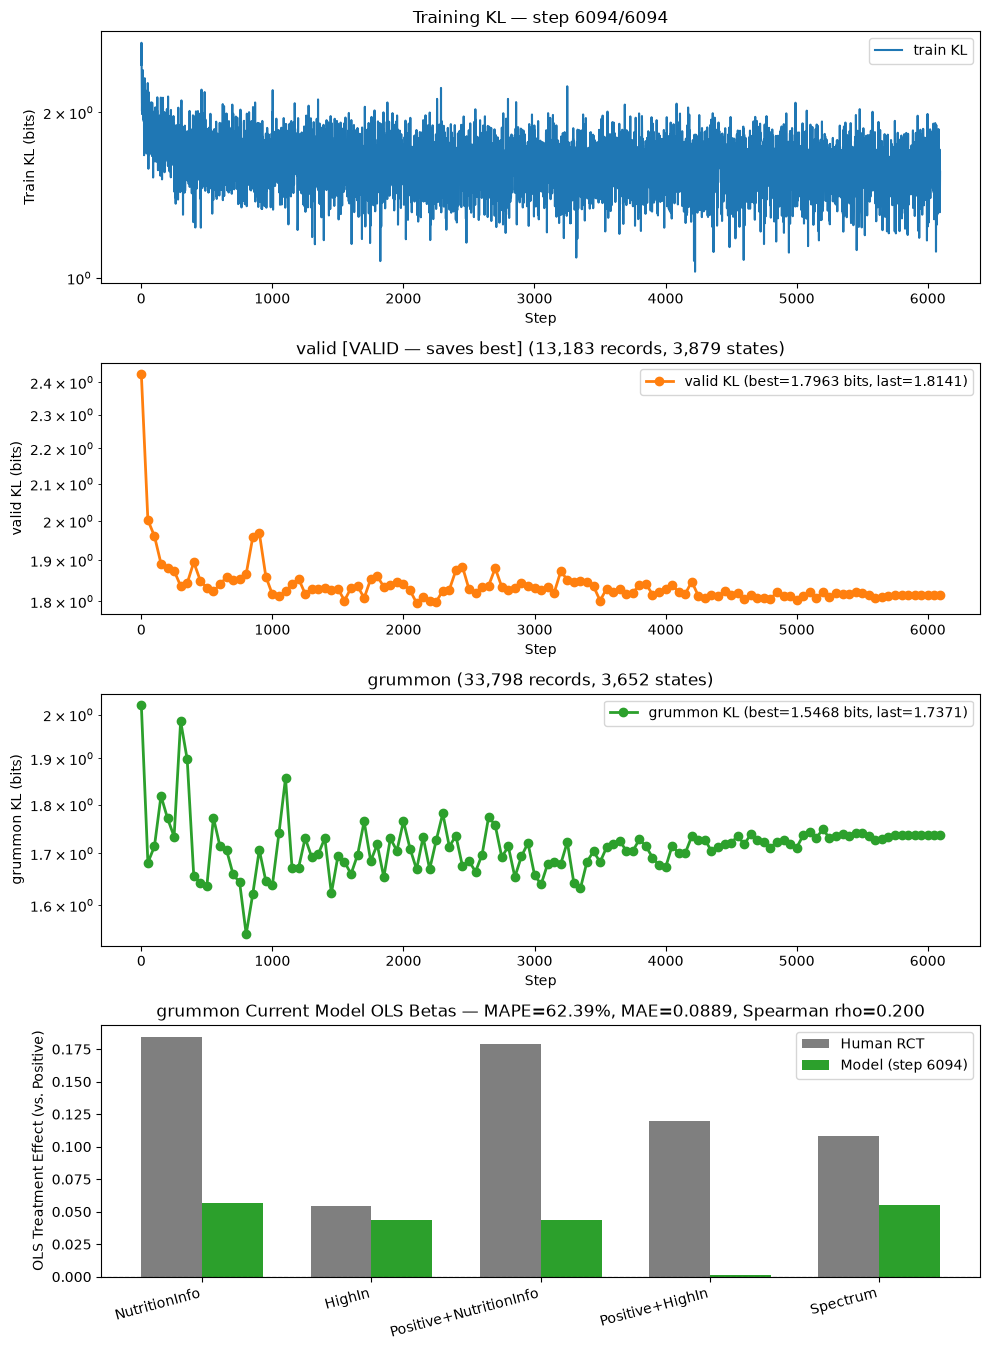

,epoch,step,train_kl,valid_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,2.4262,2.0224,104.13,0.1164,0.0149,-0.9000
1,1,50,2.2621,2.0026,1.6816,77.22,0.1100,0.0161,-0.9000
2,1,100,1.9007,1.9610,1.7141,75.93,0.1040,0.0140,-0.9000
3,1,150,2.1285,1.8916,1.8186,74.18,0.1026,0.0136,-0.9000
4,1,200,1.7250,1.8806,1.7712,74.81,0.0971,0.0112,-0.4000
5,1,250,1.8060,1.8739,1.7339,58.25,0.0718,0.0057,-0.2000
6,1,300,1.8502,1.8366,1.9849,71.93,0.0912,0.0093,-0.1000
7,1,350,1.7976,1.8435,1.8977,55.75,0.0830,0.0093,-0.3000
8,1,400,1.5237,1.8949,1.6557,52.04,0.0740,0.0071,0.1000
9,1,450,1.3943,1.8496,1.6428,68.33,0.0860,0.0083,-0.1000


,human,model,abs_diff
NutritionInfo,0.1844,0.0565,0.1279
HighIn,0.0541,0.0436,0.0105
Positive+NutritionInfo,0.1788,0.0435,0.1354
Positive+HighIn,0.1194,0.0016,0.1178
Spectrum,0.1083,0.0554,0.0529


In [4]:
plotter = trainer.train()

## Optional: Probe VRAM directly on `trainer`

`trainer.probe_vram(grid)` reuses `trainer.train_one_step` with a zero-LR AdamW optimizer (and 2 micro-batches when `grad_accum_steps > 1`) inside `torch.random.fork_rng` so it measures exact steady-state peak VRAM without mutating model weights, RNG state, or creating empty plots.

In [8]:
df_probe = trainer.probe_vram([
    (32, 16_000),
    (32, 20_000),
    (32, 24_000),
    (64, 24_000),
    (96, 36_000),
    (128, 48_000),
    (160, 60_000),
])
display(df_probe)

# You can also update grouping on the fly and recompute the schedule:
# trainer.set_grouping(max_questions_per_group=160, max_chars_per_group=60_000)

GPU: NVIDIA GeForce RTX 5090 (31.4 GiB total)
mq= 32, mc= 16000 -> OK  | peak_alloc=20.92 GiB (reserved=21.64 GiB) | worst=(26, 110, 131) (3,516 toks) | 1ep_steps=6,693
mq= 32, mc= 20000 -> OK  | peak_alloc=25.52 GiB (reserved=25.94 GiB) | worst=(20, 105, 221) (4,525 toks) | 1ep_steps=6,094
mq= 32, mc= 24000 -> OOM | peak_alloc=27.97 GiB (reserved=28.04 GiB) | worst=(32, 102, 158) (5,158 toks) | 1ep_steps=5,771


,max_questions,max_chars,groups_per_epoch,mean_q_per_group,steps_per_epoch,total_steps_1ep,"worst_(Q, Ls, Lb)",worst_padded_toks,peak_alloc_GiB,peak_reserved_GiB,status
0,32,16000,80307,23.43,6693,6693,"(26, 110, 131)",3516,20.92,21.64,OK
1,32,20000,73125,25.74,6094,6094,"(20, 105, 221)",4525,25.52,25.94,OK
2,32,24000,69249,27.18,5771,5771,"(32, 102, 158)",5158,27.97,28.04,OOM


## Show train records for epoch 1 based on seed 

In [ ]:
import random
from data.base import group_train_records


def epoch1_question_order(seed):
    epoch_rng = random.Random(f"{seed}:epoch:0")
    sampled = (
        epoch_rng.sample(train_records, trainer.n_per_epoch)
        if trainer.samples_per_epoch is not None
        else train_records
    )
    groups = group_train_records(
        sampled,
        max_questions=trainer_cfg["max_questions_per_group"],
        max_chars=trainer_cfg["max_chars_per_group"],
        rng=epoch_rng,
    )
    bs = trainer.effective_groups_bs
    return pd.DataFrame(
        [
            {
                "step": (group_idx // bs) + 1,
                "group_idx": group_idx,
                "n_questions": len(g),
                "persona": g[0]["persona"],
                "qids": [r["qid"] for r in g],
            }
            for group_idx, g in enumerate(groups)
        ]
    )


In [ ]:
SEED_TO_CHECK = 0
df_order = epoch1_question_order(SEED_TO_CHECK)
print(
    f"seed={SEED_TO_CHECK} | groups={len(df_order):,} | "
    f"steps={df_order['step'].max():,} | questions={df_order['n_questions'].sum():,}"
)
display(df_order)

seed=0 | groups=42,219 | steps=3,519 | questions=1,881,950


,step,group_idx,n_questions,persona,qids
0,1,0,62,"Sex=Male, Age=50-64, Education=College graduat...","[2018:v24, 2018:v23, 2018:v63, 2018:v22, 2018:..."
1,1,1,47,"Sex=Female, Age=30-49, Education=High school o...","[2024:v23, 2024:v24, 2024:v30, 2024:v26, 2024:..."
2,1,2,1,"Sex=Female, Age=65+, Education=College graduat...",[twin2k:QID57]
3,1,3,35,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID278_5, twin2k:QID277_12, twin2k:QID..."
4,1,4,96,"Sex=Female, Age=18-29, Education=High school o...","[twin2k:QID148, twin2k:QID169, twin2k:QID275, ..."
...,...,...,...,...,...
42214,3518,42214,73,"Sex=Female, Age=50-64, Education=College gradu...","[twin2k:QID233_5, twin2k:QID26_8, twin2k:QID9_..."
42215,3518,42215,75,"Sex=Male, Age=18-29, Education=High school or ...","[twin2k:QID171, twin2k:QID233_3, twin2k:QID9_0..."
42216,3519,42216,54,"Sex=Female, Age=50-64, Education=High school o...","[2017:v54, 2017:v55, 2017:v42, 2017:v60, 2017:..."
42217,3519,42217,54,"Sex=Male, Age=50-64, Education=College graduat...","[2017:v54, 2017:v55, 2017:v42, 2017:v60, 2017:..."


In [ ]:
SEED_TO_CHECK = 1
df_order = epoch1_question_order(SEED_TO_CHECK)
print(
    f"seed={SEED_TO_CHECK} | groups={len(df_order):,} | "
    f"steps={df_order['step'].max():,} | questions={df_order['n_questions'].sum():,}"
)
display(df_order)

seed=1 | groups=42,219 | steps=3,519 | questions=1,881,950


,step,group_idx,n_questions,persona,qids
0,1,0,96,"Sex=Female, Age=30-49, Education=College gradu...","[twin2k:QID148, twin2k:QID167, twin2k:QID275, ..."
1,1,1,62,"Sex=Male, Age=65+, Education=College graduate/...","[twin2k:QID245_5, twin2k:QID245_4, twin2k:QID2..."
2,1,2,55,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID150, twin2k:QID236_5, twin2k:QID236..."
3,1,3,62,"Sex=Female, Age=30-49, Education=College gradu...","[2018:v24, 2018:v23, 2018:v63, 2018:v22, 2018:..."
4,1,4,21,"Sex=Male, Age=50-64, Education=Associate's deg...","[twin2k:QID29_22, twin2k:QID29_17, twin2k:QID2..."
...,...,...,...,...,...
42214,3518,42214,6,"Sex=Male, Age=30-49, Education=College graduat...","[2017:v22, 2017:v48, 2017:v52, 2017:v50, 2017:..."
42215,3518,42215,56,"Sex=Male, Age=65+, Education=College graduate/...","[2021:v52, 2021:v40, 2021:v42, 2021:v51, 2021:..."
42216,3519,42216,73,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID9_276, twin2k:QID31, twin2k:QID25_4..."
42217,3519,42217,96,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID148, twin2k:QID167, twin2k:QID275, ..."
